# Photoelectric effect. LED I–V measurements and $h/e$

0.1.0 Initial

0.2.0 Seven new diodes with measured spectrum

0.2.1 Observed band instead of nominal

0.2.2 Fit by wl low end observed with optical scope - does not improve

0.2.3 Fit by wl observed with digital scope - does not improve

0.3.0 Data cleaning with flags (saturation, range limit, dropouts, outliers); baseline subtraction; two threshold definitions (linear extrapolation and voltage at fixed current); LED model with offset; weighted fit of $V_b(\nu)$ with uncertainties

# Resume

*(numbers from the run on `forward.csv`, 2026-11-19)*

**What we measure.** The DIY sourcemeter sweeps the voltage on each LED (with its ~100 Ω ballast resistor) and measures the current. The usable range is about **5 nA – 12 µA**: below it is noise (≈1 nA), above it the source reaches its limit — the measured voltage stops following the set voltage and the current saturates. So the LEDs work in the exponential part of the I–V curve, far below the normal operating current (~10 mA). The voltage drop on the ballast resistor is ≤ 1.2 mV and is negligible.

**Cleaning.** Every point is flagged (no current, over-range, LO-range limit, saturation, noise floor, outliers). We use the *measured* voltage, so the points taken while the source could not hold the set voltage are kept: they lie on the same I–V curve. This gives **67–98 clean points per LED** instead of 3–7 before (the old cut `MAX_CURRENT = 10e-8` was 100 nA, not mA). The 405 nm sweep has a contact dropout at $V > 2.87$ V; these points are removed.

**Threshold voltage $V_b$.** On an exponential curve there is no unique turn-on point. Two definitions are used:
* **A. Linear extrapolation** of the upper part of the curve ($I > I_\max/4$, 28–57 points) to $I = 0$ — the method of the lab manual;
* **B. Voltage at a fixed current** $I_\text{ref}$, the same for all LEDs.

**Model.** $V_b = \dfrac{h}{e}\nu + V_\text{off}$. Only the slope is meaningful.

**Results.**

| method | $h/e$, $10^{-15}$ V s | vs accepted | offset, V |
|---|---|---|---|
| A. linear extrapolation | 4.42 ± 0.27 | +7 % | −0.66 ± 0.15 |
| B. $I_\text{ref}$ = 10 nA | 4.14 ± 0.23 | 0 % | −0.80 ± 0.13 |
| B. $I_\text{ref}$ = 100 nA | 4.30 ± 0.25 | +4 % | −0.76 ± 0.14 |
| B. $I_\text{ref}$ = 3 µA | 4.51 ± 0.27 | +9 % | −0.71 ± 0.15 |

* All values agree with $h/e = 4.136\times10^{-15}$ V s within 1.5σ. The fit uncertainty is ±6 %, so the agreement within 1–2 % claimed earlier was partly luck.
* $V_b$ is **lower** than $h\nu/e$ for every LED, by 0.3–0.9 V depending on the LED and on $I_\text{ref}$ (method A: 0.33–0.61 V). The fitted offset (≈ −0.7 V) is an extrapolation to $\nu = 0$, far from the data; the per-LED values $V_b - h\nu/e$ are more informative.
* **Systematic drift of the slope with $I_\text{ref}$.** The InGaN LEDs (395–525 nm) have a larger ideality factor ($n \approx 2.7$–3.5) than the AlGaInP LEDs (590–640 nm, $n \approx 2.2$–2.3). Their voltage grows faster with current, so the high-frequency points rise more and the slope increases with $I_\text{ref}$. This systematic effect (~9 % over 2.5 decades) is larger than the statistical error.
* The offset depends on the material: at the same $I_\text{ref}$ the AlGaInP LEDs have $V_b - h\nu/e$ more negative than the InGaN LEDs at the long-wavelength end (e.g. 525 nm vs 590 nm).

**Instrument notes.**
* At the LO→HI range switch (~150 nA) the HI range reads 1.2–1.6× more current than the LO range extrapolates to (≈ 10–35 mV along $V$). This shifts all LEDs similarly; it affects the offset, not the slope. Worth a calibration check of the DIY sourcemeter.
* The 620 nm LED has no entry in the spectrum table (there is 624 → 621 nm); the nominal value ± 10 nm is used.

# LED equation

$$
V_b = \frac{h}{e}\,\nu + V_\text{off}, \qquad \nu = \frac{c}{\lambda}
$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.constants import h, elementary_charge as e, speed_of_light as c, k as k_B

HE_ACCEPTED = h / e          # V s
VT = k_B * 296 / e           # thermal voltage at ~23 C, V

try:
    import subprocess
    subprocess.run(['wget', '-q', 'https://raw.githubusercontent.com/tphlabs/data/refs/heads/main/Lab4_SP/spectrumplots.py',
                    '-O', 'spectrumplots.py'], check=True, timeout=20)
    from spectrumplots import wavelength_to_color
except Exception:
    def wavelength_to_color(wl):
        """Fallback: rough visible-spectrum colour."""
        cmap = plt.get_cmap('turbo')
        return cmap(np.clip((wl - 380) / (700 - 380), 0, 1))

# LED spectra measured with the digital spectrometer

Observed peak wavelengths and their uncertainty, see the [measurements dataset](https://github.com/evgeny-kolonsky/Lab4/tree/main/PE/2026.11/AVANTES).
If an LED is not in the table, the nominal wavelength with ±10 nm is used and a warning is printed.

In [2]:
SPECTRA = pd.read_csv(pd.io.common.StringIO("""wl_nominal,wl_peak,wl_err
395,398,8
405,401,6
420,419,8
460,469,11
470,448,8
525,529,16
590,590,7
624,621,8
640,650,10
"""))

_warned = set()

def observed_wavelength(wl_nominal, default_err=10):
    row = SPECTRA[SPECTRA.wl_nominal == wl_nominal]
    if row.empty:
        if wl_nominal not in _warned:
            print(f'WARNING: no measured spectrum for {wl_nominal:.0f} nm, using nominal ± {default_err} nm')
            _warned.add(wl_nominal)
        return float(wl_nominal), float(default_err)
    return float(row.wl_peak.iloc[0]), float(row.wl_err.iloc[0])

# Load the data

In [3]:
URL = 'https://raw.githubusercontent.com/evgeny-kolonsky/Lab4/refs/heads/main/PE/2026.11/DIY/'
NAME = 'forward'

try:
    raw = pd.read_csv(URL + f'{NAME}.csv')
except Exception:
    raw = pd.read_csv(f'{NAME}.csv')          # local copy
print(raw.shape)
raw.head()

(1533, 16)


,timestamp,wavelength_nm,led_mode,led_V,led_mA,V_set_V,V_meas_V,I_nA,I_std_nA,over_range,range,background_run,linear_limit_nA,zero_offset_nA,I_at_0V_nA,dark_after_nA
0,2026-11-19 08:53:19,395,mA,15.0,3.0,1.00,1.0003,-1.9310,1.2325,0,LO,0,154.7,1.749,-1.256,-1.6117
1,2026-11-19 08:53:19,395,mA,15.0,3.0,1.01,1.0102,-2.0786,1.2098,0,LO,0,154.7,1.749,-1.256,-1.6117
2,2026-11-19 08:53:19,395,mA,15.0,3.0,1.02,1.0200,-2.3465,1.1035,0,LO,0,154.7,1.749,-1.256,-1.6117
3,2026-11-19 08:53:19,395,mA,15.0,3.0,1.03,1.0300,-2.4819,0.7417,0,LO,0,154.7,1.749,-1.256,-1.6117
4,2026-11-19 08:53:19,395,mA,15.0,3.0,1.04,1.0400,-2.7002,0.4855,0,LO,0,154.7,1.749,-1.256,-1.6117


# Cleaning

Every point gets a flag; only `ok` points are used.

| flag | rule |
|---|---|
| `nan` | current not measured |
| `over_range` | instrument over-range flag |
| `LO_limit` | LO range, current above 90 % of its linear limit |
| `saturated` | current at the source limit (≥ 99 % of the maximum; voltage no longer follows the set value) |
| `below_floor` | current below 5 nA (noise level ≈ 1 nA) |
| `outlier` | measured voltage deviates by more than 30 mV from the running median of its neighbours (sorted by current) — catches dropouts and reconnections |

The baseline current measured at 0 V (`I_at_0V_nA`, about −1…−2 nA) is subtracted.

We use the **measured** voltage `V_meas_V`, not the set voltage. Above ~3 µA the source cannot hold the set voltage, but the pairs (`V_meas`, `I`) still lie on the same I–V curve, so these points are kept — this is where most of the additional points come from.

In [4]:
SAT_FRAC = 0.99      # fraction of max current regarded as saturation
LO_FRAC = 0.9        # fraction of the LO-range linear limit
I_FLOOR = 5.0        # nA
V_TOL = 0.03         # V, outlier tolerance
WINDOW = 9           # points in the running median

def clean(g):
    g = g.copy()
    g['flag'] = 'ok'
    g.loc[g.I_nA.isna(), 'flag'] = 'nan'
    g.loc[g.over_range == 1, 'flag'] = 'over_range'
    g['I'] = g.I_nA - g.I_at_0V_nA                      # nA, baseline removed
    g['V'] = g.V_meas_V

    lim = g.linear_limit_nA.iloc[0]
    g.loc[(g.flag == 'ok') & (g.range == 'LO') & (g.I > LO_FRAC * lim), 'flag'] = 'LO_limit'

    i_max = g.loc[g.flag == 'ok', 'I'].max()
    g.loc[(g.flag == 'ok') & (g.I > SAT_FRAC * i_max), 'flag'] = 'saturated'
    g.loc[(g.flag == 'ok') & (g.I < I_FLOOR), 'flag'] = 'below_floor'

    s = g[g.flag == 'ok'].sort_values('I')
    v_med = s.V.rolling(WINDOW, center=True, min_periods=3).median()
    g.loc[s.index[(s.V - v_med).abs() > V_TOL], 'flag'] = 'outlier'
    return g

data = pd.concat([clean(g) for _, g in raw.groupby('wavelength_nm')])
WLS = np.sort(data.wavelength_nm.unique())

summary = data.groupby(['wavelength_nm', 'flag']).size().unstack(fill_value=0)
summary

flag,LO_limit,below_floor,nan,ok,outlier,over_range,saturated
wavelength_nm,,,,,,,
395,1,127,0,67,0,0,6
405,1,128,0,68,1,1,2
420,1,117,0,69,0,0,14
460,1,75,0,98,0,0,27
525,1,58,1,91,0,0,17
590,1,28,0,87,0,0,85
620,1,23,0,92,0,0,85
640,1,0,1,91,0,0,66


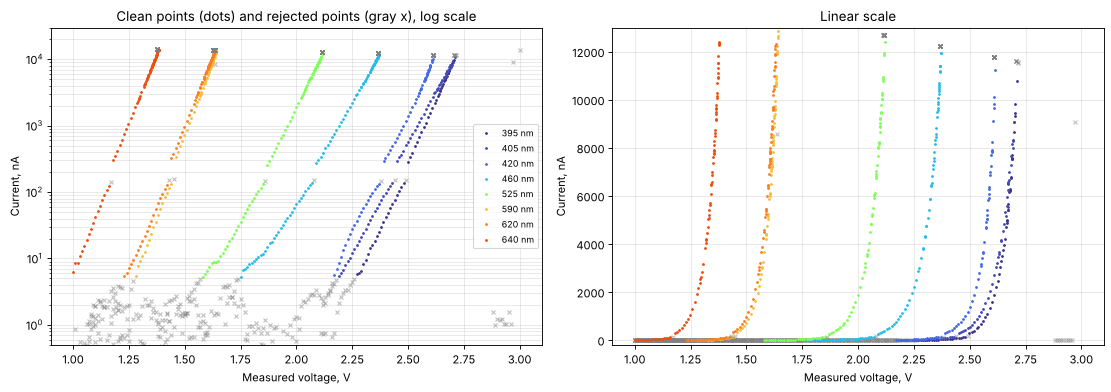

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for wl in WLS:
    g = data[data.wavelength_nm == wl]
    ok = g.flag == 'ok'
    col = wavelength_to_color(wl)
    for ax in axes:
        ax.plot(g.V[ok], g.I[ok], '.', ms=3, color=col, label=f'{wl:.0f} nm')
        ax.plot(g.V[~ok], g.I[~ok].clip(lower=0.1), 'x', ms=4, color='gray', alpha=0.5)
axes[0].set_yscale('log'); axes[0].set_ylim(0.5, 3e4)
axes[1].set_ylim(-200, 1.3e4)
for ax in axes:
    ax.set_xlabel('Measured voltage, V'); ax.set_ylabel('Current, nA'); ax.grid(True, which='both', alpha=0.3)
axes[0].legend(fontsize=8)
axes[0].set_title('Clean points (dots) and rejected points (gray x), log scale')
axes[1].set_title('Linear scale')
plt.tight_layout(); plt.show()

# Threshold voltage

**A. Linear extrapolation.** A straight line is fitted to the clean points in the upper current window $[I_\max/4,\ I_\max]$; $V_b$ is where it crosses $I=0$.

**B. Voltage at fixed current.** $\ln I$ vs $V$ is fitted with a straight line in the window $I_\text{ref}/2 \dots 2I_\text{ref}$; $V_b = V(I_\text{ref})$. The slope of this fit also gives the ideality factor $n$: $I \propto \exp\!\left(V/nV_T\right)$.

For an exponential curve both definitions depend on the current where they are applied — that is why the offset is not universal.

In [6]:
def vb_linear(g, frac=0.25):
    s = g[g.flag == 'ok']
    m = s.I > frac * s.I.max()
    (a, b), cov = np.polyfit(s.V[m], s.I[m], 1, cov=True)
    vb = -b / a
    # uncertainty from the fit covariance
    J = np.array([b / a**2, -1 / a])
    return vb, float(np.sqrt(J @ cov @ J)), int(m.sum()), (a, b, s.V[m].min())

def vb_fixed_current(g, i_ref, half_window=np.log(2)):
    s = g[g.flag == 'ok']
    y = np.log(s.I.values); x = s.V.values
    m = np.abs(y - np.log(i_ref)) < half_window
    if m.sum() < 3:
        return np.nan, np.nan, int(m.sum()), np.nan
    (p1, p0), cov = np.polyfit(x[m], y[m], 1, cov=True)
    vb = (np.log(i_ref) - p0) / p1
    J = np.array([-(np.log(i_ref) - p0) / p1**2, -1 / p1])
    return vb, float(np.sqrt(J @ cov @ J)), int(m.sum()), 1 / (p1 * VT)

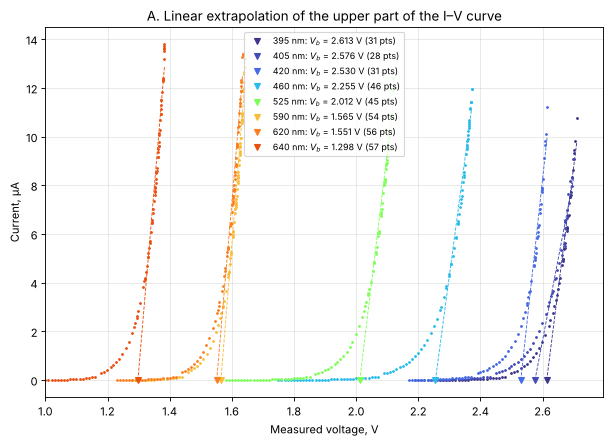

,wl_nominal,wl_peak,wl_err,Vb,Vb_err,n_pts
0,395,398.0,8.0,2.613439,0.002270,31
1,405,401.0,6.0,2.575644,0.003712,28
2,420,419.0,8.0,2.529918,0.002303,31
3,460,469.0,11.0,2.255336,0.002469,46
4,525,529.0,16.0,2.011719,0.002013,45
5,590,590.0,7.0,1.564967,0.001328,54
6,620,620.0,10.0,1.551460,0.001436,56
7,640,650.0,10.0,1.297837,0.001447,57


In [7]:
rows = []
fig, ax = plt.subplots(figsize=(9, 6))
for wl in WLS:
    g = data[data.wavelength_nm == wl]
    vb, svb, n_pts, (a, b, vmin) = vb_linear(g)
    col = wavelength_to_color(wl)
    s = g[g.flag == 'ok']
    ax.plot(s.V, s.I / 1e3, '.', ms=3, color=col)
    vv = np.linspace(vb, s.V.max(), 50)
    ax.plot(vv, (a * vv + b) / 1e3, '--', lw=0.8, color=col)
    ax.plot(vb, 0, 'v', color=col, label=f'{wl:.0f} nm: $V_b$ = {vb:.3f} V ({n_pts} pts)')
    lam, slam = observed_wavelength(wl)
    rows.append(dict(wl_nominal=wl, wl_peak=lam, wl_err=slam, Vb=vb, Vb_err=svb, n_pts=n_pts))
ax.set_xlabel('Measured voltage, V'); ax.set_ylabel('Current, µA')
ax.set_xlim(left=1); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title('A. Linear extrapolation of the upper part of the I–V curve')
plt.show()

res_lin = pd.DataFrame(rows)
res_lin

# Planck fit

$V_b$ vs $\nu = c/\lambda_\text{peak}$. The frequency uncertainty comes from the spectral width, $\sigma_\nu = c\,\sigma_\lambda/\lambda^2$. It is included by the effective-variance method: $\sigma_\text{eff}^2 = \sigma_{V}^2 + (h/e)^2\sigma_\nu^2$.

h/e = 4.4154e-15 ± 2.7e-16 V s  (+6.8 % from accepted)
offset = -0.66 ± 0.15 V


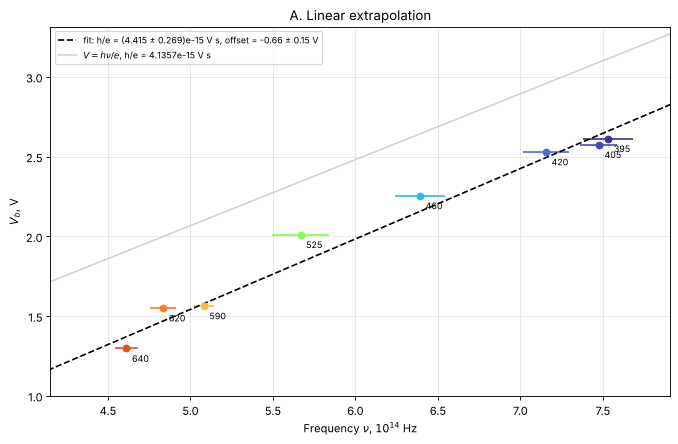

,wl_nominal,wl_peak,Vb,Vb_err,n_pts,dV
0,395,398.0,2.613,0.002,31,-0.502
1,405,401.0,2.576,0.004,28,-0.516
2,420,419.0,2.530,0.002,31,-0.429
3,460,469.0,2.255,0.002,46,-0.388
4,525,529.0,2.012,0.002,45,-0.332
5,590,590.0,1.565,0.001,54,-0.536
6,620,620.0,1.551,0.001,56,-0.448
7,640,650.0,1.298,0.001,57,-0.610


In [8]:
def planck_fit(res, title='', ax=None):
    r = res.dropna(subset=['Vb']).copy()
    nu = c / (r.wl_peak.values * 1e-9)
    s_nu = c * r.wl_err.values * 1e-9 / (r.wl_peak.values * 1e-9) ** 2
    V, sV = r.Vb.values, np.maximum(r.Vb_err.values, 1e-3)
    p = np.polyfit(nu, V, 1)
    for _ in range(5):                                      # effective variance iterations
        sig = np.sqrt(sV**2 + (p[0] * s_nu) ** 2)
        p, cov = curve_fit(lambda x, k, b: k * x + b, nu, V, p0=p, sigma=sig, absolute_sigma=False)
    he, off = p
    she, soff = np.sqrt(np.diag(cov))
    r['nu'] = nu
    r['dV'] = V - HE_ACCEPTED * nu                        # V_b - h nu / e

    if ax is not None:
        for i, wl in enumerate(r.wl_nominal):
            ax.errorbar(nu[i] / 1e14, V[i], xerr=s_nu[i] / 1e14, yerr=sV[i], fmt='o', color=wavelength_to_color(wl))
            ax.annotate(f'{wl:.0f}', (nu[i] / 1e14, V[i]), textcoords='offset points', xytext=(5, -12), fontsize=8)
        nn = np.linspace(0, nu.max() * 1.05, 100)
        ax.plot(nn / 1e14, he * nn + off, 'k--', label=f'fit: h/e = ({he*1e15:.3f} ± {she*1e15:.3f})e-15 V s, offset = {off:.2f} ± {soff:.2f} V')
        ax.plot(nn / 1e14, HE_ACCEPTED * nn, color='lightgray', label=f'$V = h\\nu/e$, h/e = {HE_ACCEPTED*1e15:.4f}e-15 V s')
        ax.set_xlim(nu.min() / 1e14 * 0.9, nu.max() / 1e14 * 1.05)
        ax.set_ylim(V.min() - 0.3, (HE_ACCEPTED * nu).max() + 0.2)
        ax.set_xlabel(r'Frequency $\nu$, $10^{14}$ Hz'); ax.set_ylabel(r'$V_b$, V')
        ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc='upper left')
    return dict(he=he, she=she, off=off, soff=soff, rel=he / HE_ACCEPTED - 1, table=r)


fig, ax = plt.subplots(figsize=(10, 6))
fit_lin = planck_fit(res_lin, 'A. Linear extrapolation', ax)
plt.show()
print(f"h/e = {fit_lin['he']:.4e} ± {fit_lin['she']:.1e} V s  ({fit_lin['rel']*100:+.1f} % from accepted)")
print(f"offset = {fit_lin['off']:.2f} ± {fit_lin['soff']:.2f} V")
fit_lin['table'][['wl_nominal', 'wl_peak', 'Vb', 'Vb_err', 'n_pts', 'dV']].round(3)

# B. Voltage at fixed current

Same procedure for several reference currents. The slope should not depend on $I_\text{ref}$; the offset does.

h/e = 4.2985e-15 ± 2.5e-16 V s  (+3.9 % from accepted)


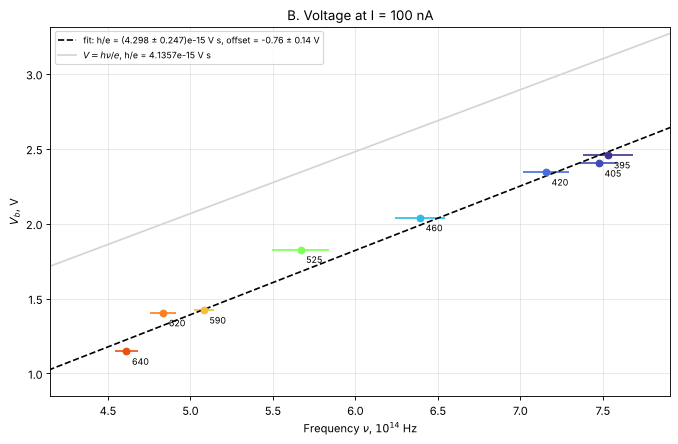

,wl_nominal,wl_peak,Vb,Vb_err,n_pts,n_ideal,dV
0,395,398.0,2.458,0.000,7,2.707,-0.657
1,405,401.0,2.403,0.000,9,3.130,-0.689
2,420,419.0,2.344,0.001,8,3.203,-0.615
3,460,469.0,2.039,0.000,10,3.544,-0.605
4,525,529.0,1.827,0.000,8,3.267,-0.517
5,590,590.0,1.422,0.001,6,2.227,-0.679
6,620,620.0,1.404,0.000,6,2.334,-0.596
7,640,650.0,1.147,0.000,6,2.268,-0.761


In [9]:
I_REFS = [10, 30, 100, 300, 1000, 3000]      # nA
I_REF_MAIN = 100                               # nA, shown in detail

def results_fixed(i_ref):
    rows = []
    for wl in WLS:
        g = data[data.wavelength_nm == wl]
        vb, svb, n_pts, n_ideal = vb_fixed_current(g, i_ref)
        lam, slam = observed_wavelength(wl)
        rows.append(dict(wl_nominal=wl, wl_peak=lam, wl_err=slam, Vb=vb, Vb_err=svb, n_pts=n_pts, n_ideal=n_ideal))
    return pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 6))
fit_main = planck_fit(results_fixed(I_REF_MAIN), f'B. Voltage at I = {I_REF_MAIN} nA', ax)
plt.show()
print(f"h/e = {fit_main['he']:.4e} ± {fit_main['she']:.1e} V s  ({fit_main['rel']*100:+.1f} % from accepted)")
fit_main['table'][['wl_nominal', 'wl_peak', 'Vb', 'Vb_err', 'n_pts', 'n_ideal', 'dV']].round(3)

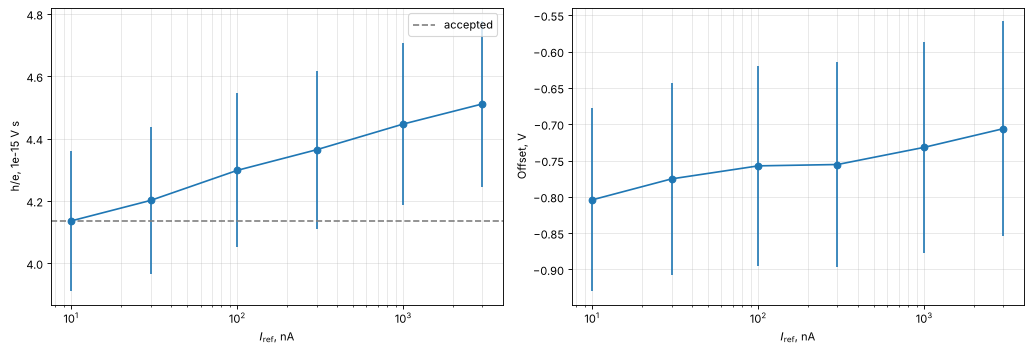

,I_ref_nA,he,he_err,rel_percent,offset,offset_err
0,10,4.136328e-15,2.255968e-16,0.0,-0.80,0.13
1,30,4.201871e-15,2.366969e-16,1.6,-0.78,0.13
2,100,4.298471e-15,2.470237e-16,3.9,-0.76,0.14
3,300,4.364479e-15,2.538602e-16,5.5,-0.76,0.14
4,1000,4.447053e-15,2.598585e-16,7.5,-0.73,0.14
5,3000,4.511601e-15,2.652344e-16,9.1,-0.71,0.15
6,linear (A),4.415378e-15,2.692760e-16,6.8,-0.66,0.15


In [10]:
scan = []
for i_ref in I_REFS:
    f = planck_fit(results_fixed(i_ref))
    scan.append(dict(I_ref_nA=i_ref, he=f['he'], he_err=f['she'], rel_percent=100 * f['rel'],
                     offset=f['off'], offset_err=f['soff']))
f = fit_lin
scan.append(dict(I_ref_nA='linear (A)', he=f['he'], he_err=f['she'], rel_percent=100 * f['rel'],
                 offset=f['off'], offset_err=f['soff']))
scan = pd.DataFrame(scan)

s = scan[scan.I_ref_nA != 'linear (A)']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.errorbar(s.I_ref_nA.astype(float), s.he * 1e15, yerr=s.he_err * 1e15, fmt='o-')
ax1.axhline(HE_ACCEPTED * 1e15, color='gray', ls='--', label='accepted')
ax1.set_ylabel('h/e, 1e-15 V s')
ax2.errorbar(s.I_ref_nA.astype(float), s.offset, yerr=s.offset_err, fmt='o-')
ax2.set_ylabel('Offset, V')
for ax in (ax1, ax2):
    ax.set_xscale('log'); ax.set_xlabel(r'$I_\mathrm{ref}$, nA'); ax.grid(alpha=0.3, which='both')
ax1.legend()
plt.tight_layout(); plt.show()

scan.round({'rel_percent': 1, 'offset': 2, 'offset_err': 2})

In [11]:
# V_b - h nu/e for every LED at several reference currents: the offset is not the same for all LEDs
dv = pd.DataFrame({f'{i} nA': results_fixed(i).set_index('wl_nominal').pipe(
        lambda r: r.Vb - HE_ACCEPTED * c / (r.wl_peak * 1e-9)) for i in I_REFS})
dv['linear (A)'] = fit_lin['table'].set_index('wl_nominal').dV
dv.round(2)

,10 nA,30 nA,100 nA,300 nA,1000 nA,3000 nA,linear (A)
wl_nominal,,,,,,,
395,-0.80,-0.74,-0.66,-0.61,-0.54,-0.48,-0.50
405,-0.86,-0.78,-0.69,-0.64,-0.55,-0.47,-0.52
420,-0.76,-0.70,-0.62,-0.57,-0.48,-0.41,-0.43
460,-0.82,-0.71,-0.60,-0.55,-0.45,-0.37,-0.39
525,-0.70,-0.61,-0.52,-0.46,-0.38,-0.32,-0.33
590,-0.79,-0.74,-0.68,-0.65,-0.59,-0.53,-0.54
620,-0.73,-0.66,-0.60,-0.56,-0.50,-0.44,-0.45
640,-0.88,-0.82,-0.76,-0.73,-0.66,-0.60,-0.61


# Instrument check: LO/HI range consistency

Fit $\ln I$ vs $V$ separately on the LO range (10–60 nA) and on the HI range (300–1500 nA), and compare the voltages where both reach 150 nA. A negative $\Delta V$ means the HI range reads a higher current.

In [12]:
rows = []
for wl in WLS:
    g = data[(data.wavelength_nm == wl) & (data.flag == 'ok')]
    lo = g[(g.range == 'LO') & g.I.between(10, 60)]
    hi = g[(g.range == 'HI') & g.I.between(300, 1500)]
    plo = np.polyfit(lo.V, np.log(lo.I), 1)
    phi = np.polyfit(hi.V, np.log(hi.I), 1)
    v_lo = (np.log(150) - plo[1]) / plo[0]
    v_hi = (np.log(150) - phi[1]) / phi[0]
    rows.append(dict(wl=wl, n_LO=1 / (plo[0] * VT), n_HI=1 / (phi[0] * VT), dV_mV=1e3 * (v_hi - v_lo),
                     current_ratio=np.exp(plo[0] * (v_lo - v_hi))))
pd.DataFrame(rows).round(2)

,wl,n_LO,n_HI,dV_mV,current_ratio
0,395,2.48,2.32,-20.50,1.38
1,405,2.72,2.80,-20.39,1.34
2,420,2.36,2.77,-9.54,1.17
3,460,3.58,2.98,-34.64,1.46
4,525,2.84,2.56,-17.86,1.28
5,590,1.88,1.99,-18.66,1.47
6,620,2.22,2.05,-27.12,1.61
7,640,1.99,2.09,-20.57,1.50
